# ResNet on CIFAR-10 under 5M parameters

**ECE-GY 7123 Deep Learning, Project 1 (Fall 2026), NYU** · Team *Jugaad Net*: Chetan Kodeboyina (ck3399), Shwetanshu Raj (sr8250), Ninad Rade (nr3263)

We train a ResNet with **4.70M parameters** from scratch on the 50,000 CIFAR-10 training images (no pretrained weights, no external data) and predict a hidden 2,000-image test set drawn from a newer, shifted collection of images.

| | |
|---|---|
| Best public Kaggle score | **0.911** |
| Held-out accuracy (5k split, 45k-trained twin) | 98.64% |
| Parameters | 4,697,162 (limit 5,000,000) |

This notebook walks through the final model end to end: data, architecture, training recipe, training curves, inference with test-time augmentation, results and lessons. Training is not re-run here (about 75 minutes on an RTX 5070 Ti); the final checkpoint `checkpoints/best_blurzoom.pt` is loaded instead. The full write-up is in [`report/report.pdf`](report/report.pdf).

## 1. Setup

In [1]:
import re, csv, collections
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
from train import ResNet, n_params, PNGs, read_rows, DATA
from tta_balance import load, probs, tf, SHIFTS, dev

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
torch.manual_seed(0); np.random.seed(0)
print("device:", dev, "| torch", torch.__version__)
assert (DATA / "train_images").exists(), "Download the Kaggle data into data/ first (see README)" 

device: cuda | torch 2.11.0+cu128


## 2. Data

50,000 labelled 32×32 training images (5,000 per class) and 2,000 unlabelled test images. The test images come from a newer collection than the training images, which is why accuracy on them is several points lower than on held-out training images.

train: 50,000 images | test: 2,000 images
images per class: {'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


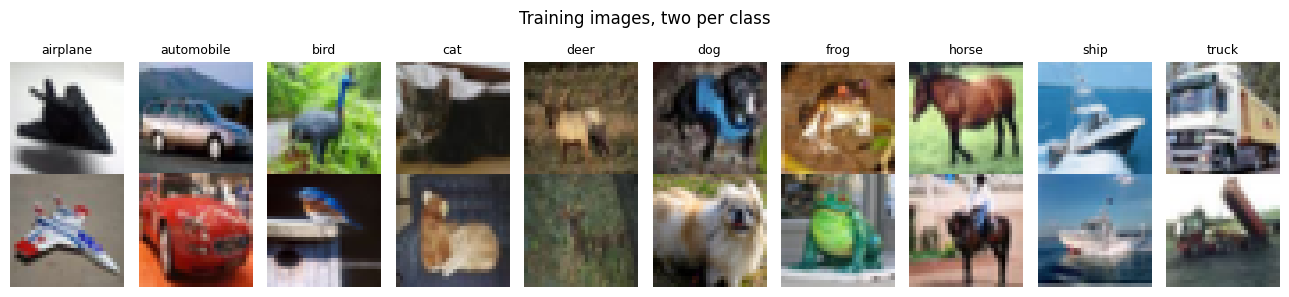

In [2]:
train_rows = read_rows(DATA / "train_labels.csv", "label")
test_rows = read_rows(DATA / "test.csv", "id")
print(f"train: {len(train_rows):,} images | test: {len(test_rows):,} images")
print("images per class:", dict(sorted(collections.Counter(CLASSES[y] for _, y in train_rows).items())))

fig, axs = plt.subplots(2, 10, figsize=(13, 3))
for c, name in enumerate(CLASSES):
    files = [f for f, y in train_rows if y == c][:2]
    for r, f in enumerate(files):
        axs[r, c].imshow(Image.open(DATA / "train_images" / f)); axs[r, c].axis("off")
    axs[0, c].set_title(name, fontsize=9)
plt.suptitle("Training images, two per class"); plt.tight_layout(); plt.show()

## 3. Model

A standard basic-block ResNet (He et al., 2016). Each block computes `ReLU(S(x) + F(x))` with `F = conv3x3 → BN → ReLU → conv3x3 → BN`, and `S` the identity or a 1×1 convolution when the shape changes. Three stages of 64, 128 and 256 channels with 4, 4 and 3 blocks; stride 2 at the start of stages 2 and 3; global average pooling and a linear classifier. Adding blocks until the parameter budget was used was one of the largest gains we found.

In [3]:
model = ResNet(C=(64, 128, 256), B=(4, 4, 3))
print(f"trainable parameters: {n_params(model):,}  (limit 5,000,000)")
assert n_params(model) <= 5_000_000

from torchsummary import summary
summary(model.to(dev), (3, 32, 32), device=str(dev).split(":")[0])

trainable parameters: 4,697,162  (limit 5,000,000)


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,728
       BatchNorm2d-2           [-1, 64, 32, 32]             128
              ReLU-3           [-1, 64, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          36,864
       BatchNorm2d-5           [-1, 64, 32, 32]             128
              ReLU-6           [-1, 64, 32, 32]               0
            Conv2d-7           [-1, 64, 32, 32]          36,864
       BatchNorm2d-8           [-1, 64, 32, 32]             128
          Identity-9           [-1, 64, 32, 32]               0
            Block-10           [-1, 64, 32, 32]               0
           Conv2d-11           [-1, 64, 32, 32]          36,864
      BatchNorm2d-12           [-1, 64, 32, 32]             128
             ReLU-13           [-1, 64, 32, 32]               0
           Conv2d-14           [-1, 64,

## 4. Training recipe

Training is done by `train.py`, configured through environment variables. The final model used:

| Part | Setting |
|---|---|
| Optimizer | SGD, Nesterov momentum 0.9, weight decay 5e-4, batch 128 |
| Schedule | learning rate 0.1, cosine decay, **400 epochs** |
| Regularization | label smoothing 0.1, EMA of weights (decay 0.999) |
| Augmentation | crop + flip, TrivialAugment, small random erasing, **CutMix** on half the batches |
| Shift-targeted augmentation | **Gaussian blur** on 20% of images, **zoom-out** (object shrunk to 60–100%) on 30% |
| Distillation | match the averaged predictions of 4 same-size teachers (pure KL, temperature 1) |
| Inference | average over 10 views: image + mirror, each with five 2-pixel shifts |

To retrain (teachers in `checkpoints/`), set `TRAIN = True` or run `scripts/pc/run_blur.ps1`:

```bash
FULL=1 MIX=1 ARCH="64,128,256;4,4,3" EPOCHS=400 SEED=41 SMOOTH=0.1 T_KD=1 A_KD=1 \
BLUR=0.2 BLUR_S=1.0 ZOOM=0.3 ZOOM_S=0.6 TAG=_blurzoom \
TEACHERS=checkpoints/best_t2_400ep.pt,checkpoints/best_t2_400ep_s14.pt,checkpoints/best_t2_400ep_s15.pt,checkpoints/best_t2_600ep.pt \
python train.py
```

In [4]:
TRAIN = False  # ~75 min on an RTX 5070 Ti; needs the four teacher checkpoints
if TRAIN:
    import os, subprocess, sys
    env = dict(os.environ, FULL="1", MIX="1", ARCH="64,128,256;4,4,3", EPOCHS="400", SEED="41", SMOOTH="0.1", T_KD="1", A_KD="1",
               BLUR="0.2", BLUR_S="1.0", ZOOM="0.3", ZOOM_S="0.6", TAG="_blurzoom",
               TEACHERS=",".join(f"checkpoints/{t}.pt" for t in ["best_t2_400ep", "best_t2_400ep_s14", "best_t2_400ep_s15", "best_t2_600ep"]))
    subprocess.run([sys.executable, "train.py"], env=env, check=True)
else:
    print("Skipping training; using checkpoints/best_blurzoom.pt")

Skipping training; using checkpoints/best_blurzoom.pt


### Augmentation examples

What the model sees during training: each row is one image and eight random augmented versions. The last row shows CutMix, where a patch from another image is pasted in and the label is mixed by area.

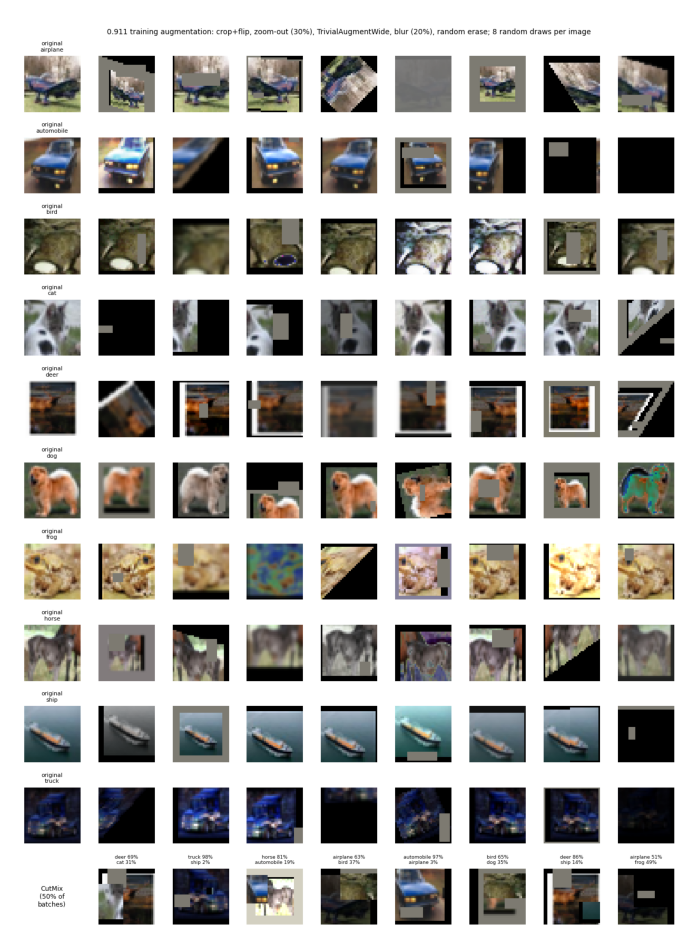

In [5]:
plt.figure(figsize=(9, 12)); plt.imshow(Image.open("figures/augment_samples.png")); plt.axis("off"); plt.show()

## 5. Training curves

One line per epoch in the training log. Because the final model trains on all 50,000 images, its printed "val acc" is measured on training images and is only a sanity check. The loss falls steadily until the learning rate approaches zero around epoch 375.

400 epochs logged, final training loss 0.039


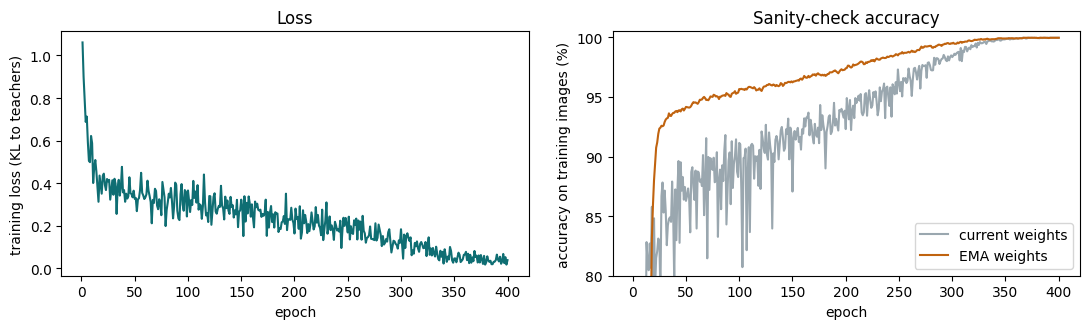

In [6]:
LINE = re.compile(r"ep\s+(\d+)/(\d+)\s+loss ([\d.]+)\s+val acc ([\d.]+)\s+raw ([\d.]+)")
log = pd.DataFrame([m.groups() for m in LINE.finditer(Path("logs/train_log_final.txt").read_text(encoding="utf-8"))],
                   columns=["epoch", "of", "loss", "ema_acc", "raw_acc"]).astype(float)
print(f"{len(log)} epochs logged, final training loss {log.loss.iloc[-1]:.3f}")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4))
a.plot(log.epoch, log.loss, color="#0f6e73"); a.set(xlabel="epoch", ylabel="training loss (KL to teachers)", title="Loss")
b.plot(log.epoch, log.raw_acc * 100, label="current weights", color="#9aa7af")
b.plot(log.epoch, log.ema_acc * 100, label="EMA weights", color="#c0630f")
b.set(xlabel="epoch", ylabel="accuracy on training images (%)", title="Sanity-check accuracy", ylim=(80, 100.5)); b.legend()
plt.tight_layout(); plt.show()

## 6. Inference with test-time augmentation

Load the final checkpoint and predict the 2,000 test images, averaging softmax outputs over 10 views. The result should match the submitted file `results/submission_final_0.911.csv`.

loaded final model: 4,697,162 parameters


agreement with the submitted file: 100.00%


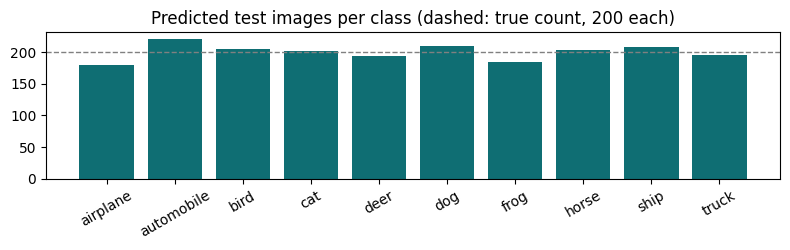

In [7]:
final = load("checkpoints/best_blurzoom.pt")
print(f"loaded final model: {n_params(final):,} parameters")
test = PNGs(test_rows, DATA / "test_images", tf)
P = probs(final, test, SHIFTS)
pred = P.argmax(1).numpy()

Path("results").mkdir(exist_ok=True)
pd.DataFrame({"id": [i for _, i in test_rows], "label": pred}).to_csv("results/submission.csv", index=False)
saved = pd.read_csv("results/submission_final_0.911.csv").sort_values("id").label.to_numpy()
print(f"agreement with the submitted file: {(saved == pred).mean():.2%}")

counts = np.bincount(pred, minlength=10)
plt.figure(figsize=(8, 2.6)); plt.bar(CLASSES, counts, color="#0f6e73"); plt.axhline(200, ls="--", color="grey", lw=1)
plt.title("Predicted test images per class (dashed: true count, 200 each)"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

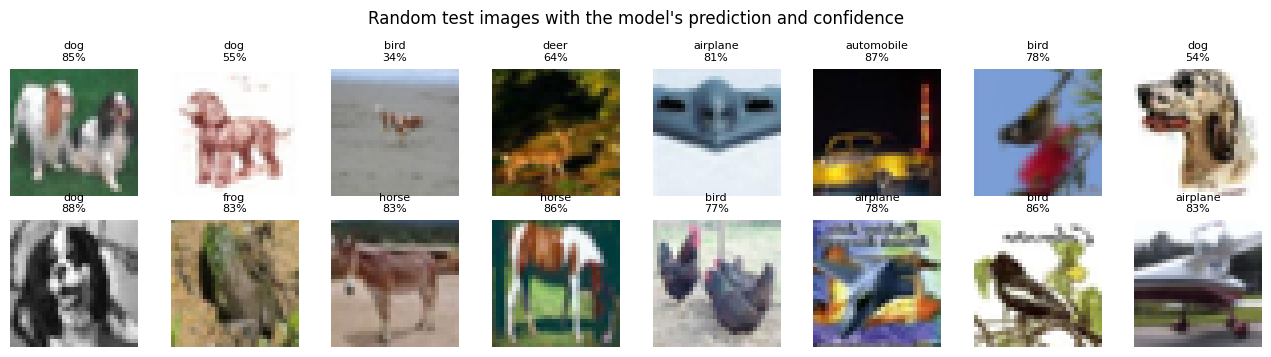

In [8]:
conf = P.max(1).values.numpy()
idx = np.random.choice(len(test_rows), 16, replace=False)
fig, axs = plt.subplots(2, 8, figsize=(13, 3.6))
for ax, i in zip(axs.flat, idx):
    ax.imshow(Image.open(DATA / "test_images" / test_rows[i][0])); ax.axis("off")
    ax.set_title(f"{CLASSES[pred[i]]}\n{conf[i]:.0%}", fontsize=8)
plt.suptitle("Random test images with the model's prediction and confidence"); plt.tight_layout(); plt.show()

## 7. Results across all experiments

About 30 training runs and 28 Kaggle submissions. Public scores use roughly 1,000 of the 2,000 hidden images, so they are noisy by about ±0.01. Full details are in `docs/EXPERIMENTS.md` and the report.

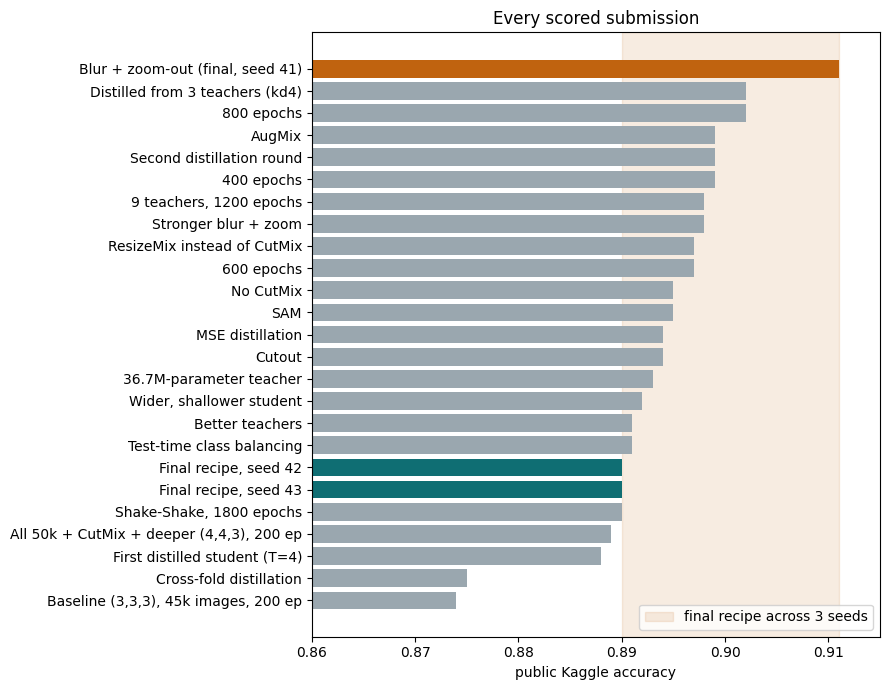

In [9]:
scores = pd.DataFrame([
    ("Baseline (3,3,3), 45k images, 200 ep", 0.874), ("All 50k + CutMix + deeper (4,4,3), 200 ep", 0.889),
    ("400 epochs", 0.899), ("600 epochs", 0.897), ("SAM", 0.895), ("Test-time class balancing", 0.891),
    ("First distilled student (T=4)", 0.888), ("Cross-fold distillation", 0.875), ("Distilled from 3 teachers (kd4)", 0.902),
    ("Second distillation round", 0.899), ("9 teachers, 1200 epochs", 0.898), ("MSE distillation", 0.894),
    ("36.7M-parameter teacher", 0.893), ("Wider, shallower student", 0.892), ("Blur + zoom-out (final, seed 41)", 0.911),
    ("Stronger blur + zoom", 0.898), ("AugMix", 0.899), ("Cutout", 0.894), ("No CutMix", 0.895), ("Better teachers", 0.891),
    ("Shake-Shake, 1800 epochs", 0.890), ("800 epochs", 0.902), ("ResizeMix instead of CutMix", 0.897),
    ("Final recipe, seed 42", 0.890), ("Final recipe, seed 43", 0.890)], columns=["run", "public"])
s = scores.sort_values("public")
colors = ["#c0630f" if "seed 41" in r else "#0f6e73" if "Final recipe" in r else "#9aa7af" for r in s.run]
plt.figure(figsize=(9, 7)); plt.axvspan(0.89, 0.911, color="#c0630f", alpha=.12, label="final recipe across 3 seeds")
plt.barh(s.run, s.public - 0.86, left=0.86, color=colors); plt.xlim(0.86, 0.915); plt.xlabel("public Kaggle accuracy")
plt.legend(loc="lower right"); plt.title("Every scored submission"); plt.tight_layout(); plt.show()

### Seed noise

The most informative experiment came last: the exact 0.911 recipe rerun with seeds 42 and 43 scored **0.89 both times**. The best score was partly a lucky draw, and seed variance (about ±0.01) is as large as most of the changes we tried to measure.

In [10]:
seeds = pd.DataFrame({"recipe": ["t2, 400 ep"] * 3 + ["final (blur + zoom-out)"] * 3,
                      "seed": [11, 14, 15, 41, 42, 43], "public": [0.899, 0.894, 0.899, 0.911, 0.890, 0.890]})
display(seeds.pivot(index="seed", columns="recipe", values="public"))
print(seeds.groupby("recipe").public.agg(["mean", "min", "max"]).round(4))

recipe,final (blur + zoom-out),"t2, 400 ep"
seed,,
11,NaN,0.899
14,NaN,0.894
15,NaN,0.899
41,0.911,NaN
42,0.890,NaN
43,0.890,NaN


                           mean    min    max
recipe                                       
final (blur + zoom-out)  0.8970  0.890  0.911
t2, 400 ep               0.8973  0.894  0.899


## 8. Where the model still fails

All local measurements use a fixed split: the first 5,000 training images after a seed-0 shuffle are held out, and `checkpoints/best_bz45.pt` is the final recipe trained on the other 45,000. Accuracy is saturated near 98.6%, and the remaining errors are dominated by **cat ↔ dog**.

held-out accuracy: 98.64% (68 errors of 5,000)


,true -> predicted,errors
0,cat -> dog,16
1,dog -> cat,9
2,deer -> dog,3
3,cat -> frog,2
4,truck -> ship,2
5,bird -> deer,2
6,deer -> bird,2
7,bird -> dog,2


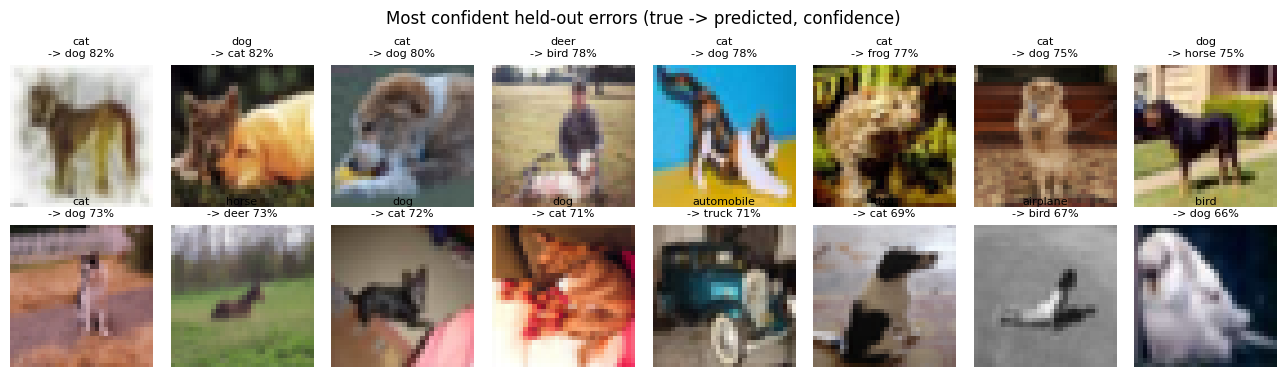

In [11]:
import random
rows = read_rows(DATA / "train_labels.csv", "label"); random.Random(0).shuffle(rows); held = rows[:5000]
y = np.array([c for _, c in held])
Ph = probs(load("checkpoints/best_bz45.pt"), PNGs(held, DATA / "train_images", tf), SHIFTS).numpy(); ph = Ph.argmax(1)
err = np.where(ph != y)[0]
print(f"held-out accuracy: {(ph == y).mean():.2%} ({len(err)} errors of {len(y):,})")
pairs = collections.Counter((CLASSES[y[i]], CLASSES[ph[i]]) for i in err).most_common(8)
display(pd.DataFrame([(f"{a} -> {b}", n) for (a, b), n in pairs], columns=["true -> predicted", "errors"]))

worst = sorted(err, key=lambda i: -Ph[i, ph[i]])[:16]
fig, axs = plt.subplots(2, 8, figsize=(13, 3.8))
for ax, i in zip(axs.flat, worst):
    ax.imshow(Image.open(DATA / "train_images" / held[i][0])); ax.axis("off")
    ax.set_title(f"{CLASSES[y[i]]}\n-> {CLASSES[ph[i]]} {Ph[i, ph[i]]:.0%}", fontsize=8)
plt.suptitle("Most confident held-out errors (true -> predicted, confidence)"); plt.tight_layout(); plt.show()

## 9. Lessons learned

1. **The basics carried most of the result.** All the training data, the full parameter budget, CutMix and 400 epochs took the score from 0.874 to 0.899.
2. **Targeting the shift helped once.** Blur and zoom-out, chosen by measuring how models fail on shifted images, gave the best score.
3. **"More" stopped helping.** Longer training, bigger teachers and stronger augmentation all scored lower on the hidden set.
4. **Held-out accuracy did not predict the leaderboard.** Every distilled variant scored 98.5–98.7% held-out, while their public scores differed by up to 0.02.
5. **Measure the noise first.** Three seeds of one recipe spanned 0.89 to 0.911; with one submission per idea, differences under about 0.02 cannot be trusted.
6. **Cat vs dog stayed the hardest pair.** It accounts for over a third of the remaining held-out errors.

See [`report/report.pdf`](report/report.pdf) for the full discussion.